# Chicago House Price Prediction

**ML CIE 2 – Activity 2: Simple House Price Prediction**

Objective: Use Linear Regression to predict house prices and check model performance.

## 1. Data and Imports

First, download the dataset from Kaggle and import the required libraries.

In [ ]:
import kagglehub
path = kagglehub.dataset_download("tawfikelmetwally/chicago-house-price")
print("Dataset downloaded at:", path)


Using Colab cache for faster access to the 'chicago-house-price' dataset.
Dataset downloaded at: /kaggle/input/chicago-house-price


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import os


## 2. Load the Data

The downloaded dataset may contain one or more files. This cell lists CSV files so you can check the file name.

In [ ]:
files = os.listdir(path)
print(files)


['realest.csv']


In [ ]:
data = pd.read_csv(path + "/realest.csv")
df = data.copy()

df.head()

,Price,Bedroom,Space,Room,Lot,Tax,Bathroom,Garage,Condition
0,53.0,2.0,967.0,5.0,39.0,652.0,1.5,0.0,0.0
1,55.0,2.0,815.0,5.0,33.0,1000.0,1.0,2.0,1.0
2,56.0,3.0,900.0,5.0,35.0,897.0,1.5,1.0,0.0
3,58.0,3.0,1007.0,6.0,24.0,964.0,1.5,2.0,0.0
4,64.0,3.0,1100.0,7.0,50.0,1099.0,1.5,1.5,0.0


## 3. About Data

Check the number of rows and columns, column names, data types, and summary statistics.

In [ ]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns)

print("\nData information:")
df.info()


Rows and columns: (157, 9)

Column names:
Index(['Price', 'Bedroom', 'Space', 'Room', 'Lot', 'Tax', 'Bathroom', 'Garage',
       'Condition'],
      dtype='object')

Data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 157 entries, 0 to 156
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Price      156 non-null    float64
 1   Bedroom    156 non-null    float64
 2   Space      146 non-null    float64
 3   Room       156 non-null    float64
 4   Lot        146 non-null    float64
 5   Tax        147 non-null    float64
 6   Bathroom   156 non-null    float64
 7   Garage     156 non-null    float64
 8   Condition  156 non-null    float64
dtypes: float64(9)
memory usage: 11.2 KB


In [ ]:
df.describe()


,Price,Bedroom,Space,Room,Lot,Tax,Bathroom,Garage,Condition
count,156.000000,156.000000,146.000000,156.000000,146.000000,147.000000,156.000000,156.000000,156.000000
mean,56.474359,3.166667,1097.246575,6.500000,32.808219,911.707483,1.480769,0.846154,0.230769
std,12.875307,1.348037,462.540698,1.675247,8.457859,443.263430,0.529408,0.808454,0.422682
min,32.000000,1.000000,539.000000,4.000000,24.000000,418.000000,1.000000,0.000000,0.000000
25%,46.000000,2.000000,805.250000,5.000000,25.000000,652.500000,1.000000,0.000000,0.000000
50%,55.000000,3.000000,965.500000,6.000000,30.000000,821.000000,1.500000,1.000000,0.000000
75%,65.000000,4.000000,1220.500000,7.000000,37.000000,1012.500000,2.000000,1.500000,0.000000
max,90.000000,8.000000,2295.000000,12.000000,50.000000,2752.000000,3.000000,2.000000,1.000000


## 4. Missing Values and Duplicate Rows

Check missing values. Remove duplicate rows and rows missing the selected price/area values after selecting the columns in the next section.

In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()


Missing values:
Price         1
Bedroom       1
Space        11
Room          1
Lot          11
Tax          10
Bathroom      1
Garage        1
Condition     1
dtype: int64

Duplicate rows: 0


## 5. Select Feature and Target

Choose one numerical feature (X), such as house area, and the numerical house price column (y). First check the column names printed above. Replace the example names below with the exact names in your dataset.

In [ ]:
FEATURE = "Space"
TARGET = "Price"

print("Feature:", FEATURE)
print("Target:", TARGET)

Feature: Space
Target: Price


In [ ]:
# Keep only the selected columns and convert them to numbers
df[FEATURE] = pd.to_numeric(df[FEATURE], errors="coerce")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

df = df.dropna(subset=[FEATURE, TARGET])
df = df[(df[FEATURE] > 0) & (df[TARGET] > 0)]

X = df[[FEATURE]]
y = df[TARGET]

print("Usable rows:", len(df))
display(df[[FEATURE, TARGET]].head())


Usable rows: 146


,Space,Price
0,967.0,53.0
1,815.0,55.0
2,900.0,56.0
3,1007.0,58.0
4,1100.0,64.0


## 6. Visualization

A scatter plot helps us see whether house area and price appear to have a relationship.

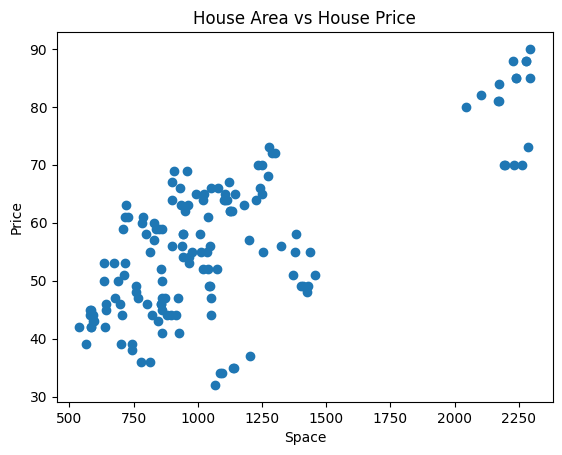

In [ ]:
plt.scatter(df[FEATURE], df[TARGET])
plt.title("House Area vs House Price")
plt.xlabel(FEATURE)
plt.ylabel(TARGET)
plt.show()


**Interpretation:** Describe whether the relationship appears positive, negative, weak, or non-linear. A visible relationship does not by itself prove causation.

## 7. Train-Test Split

Use 80% of the observations for training and 20% for testing. Test data is not used to train the model.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 116
Testing rows: 30


## 8. Model Training

Train a simple Linear Regression model and display its equation.

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

print("Equation: Predicted price =",
      round(model.intercept_, 2), "+",
      round(model.coef_[0], 2), "*", FEATURE)


Coefficient: 0.019915274341007125
Intercept: 34.39736622476674
Equation: Predicted price = 34.4 + 0.02 * Space


## 9. Predictions

Compare actual prices with predictions for test data.

In [ ]:
predicted = model.predict(X_test)

result = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": predicted
})

result.head(10)


,Actual Price,Predicted Price
0,35.0,57.140610
1,65.0,54.133403
2,58.0,50.309670
3,35.0,57.041033
4,64.0,56.383829
5,44.0,48.437635
6,61.0,55.129167
7,51.0,61.681292
8,66.0,59.152052
9,66.0,52.898656


## 10. Model Evaluation

MAE is the average absolute error, MSE is the average squared error, RMSE is in the target's units, and R² compares the model with a mean-based baseline.

In [ ]:
mae = mean_absolute_error(y_test, predicted)
mse = mean_squared_error(y_test, predicted)
rmse = mse ** 0.5
r2 = r2_score(y_test, predicted)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


MAE: 8.712082668965747
MSE: 107.29604393344825
RMSE: 10.358380372116494
R2 Score: 0.45889331820339796


## 11. Actual vs Predicted Plot

Points closer to the dashed line indicate predictions closer to actual values.

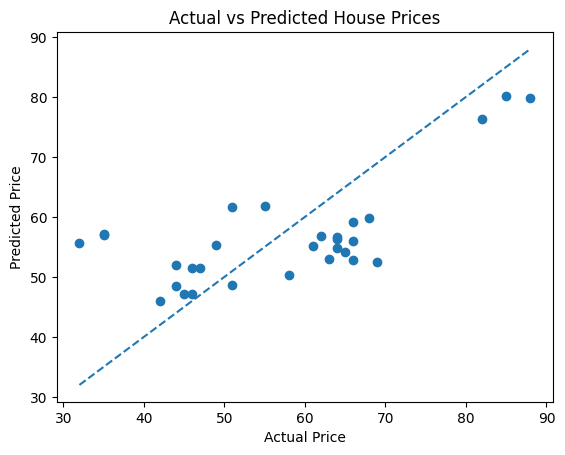

In [ ]:
plt.scatter(y_test, predicted)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)
plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.show()


## 12. Predict a New House Price

Use an area value within the training data range. The predicted price will be in the same units as the dataset's price column.

In [ ]:
# Select an example area from the middle of the training range
new_area = (X_train[FEATURE].min() + X_train[FEATURE].max()) / 2

new_house = pd.DataFrame({FEATURE: [new_area]})
new_price = model.predict(new_house)

print("New house", FEATURE, ":", new_area)
print("Predicted house price:", new_price[0])


New house Space : 1416.0
Predicted house price: 62.59739469163283


## 13. Conclusion

The Linear Regression model was trained using a numerical property feature and evaluated on separate test data. MAE, MSE, RMSE, and R² were used to check prediction performance. The model was also used to predict the price of a new house. House prices depend on many factors, such as location, size, condition, and number of rooms, so a model using one feature may have limited accuracy.